# Подбор наилучших параметров индивидуальных моделей роста рыбы заданной табличной функции роста

**Постановка задачи.**
Для моделирования роста рыбы существует целый ряд математических моделей, основанных на оценке навески рыбы определенного вида в зависимости от ее возраста в условиях достаточного питания.
С другой стороны, производители рыбных кормов предоставляют таблицы кормления (рекомендуемой нормы корма и кормовой коэффициент в зависимости от навески рыбы и температуры воды), являющиеся фактически параметрическими табличными моделями роста.
При этом, возникают вопросы соответствия традиционных математических моделей и табличных моделей.

**Назначение программы:** программа предназначена для подбора наилучших параметров шести математических моделей для наилучшего соответствия заданной табличной модели. Данные табличной модели загружаются в виде xls-файла. Соответствие математических моделей с подобранными параметрами загруженному набору данных проверяется по пяти критериям.

## Загрузка необходимых библиотек для анализа

In [3]:
#для работы с датасетами
import pandas as pd

#для работы с математическими вычислениями с базовыми функциями
import numpy as np
import math
from numpy.ma.core import exp
from scipy.special import expit # для работы с экспонентой, исключает переполнение


from scipy.optimize import least_squares # решение нелинейной задачи наименьших квадратов с ограничениями на переменные.
from scipy.optimize import leastsq # наименьший квадрат для подгонки  используется только lm
from scipy.optimize import curve_fit

#для работы с графиками
import matplotlib.pyplot as plt
import seaborn as sns

# метрики
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Загрузка данных и их обработка

Данные смоделированы за период длиной 275 дней, и начальным весом малька 20 г.

In [4]:
# # из библиотеки google.colab импортируем класс files
# from google.colab import files

# # создаем объект этого класса, применяем метод .upload()
# uploaded = files.upload()

In [5]:
data_all=pd.read_excel('file_with_data.xlsx')
data_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 275 entries, 0 to 274
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    275 non-null    int64  
 1   data    275 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 4.4 KB


Пострение полученных данных на графике.

In [6]:
# Нарисовать динамику роста
def picture(name_feed):
  ''' name_feed - строковая переменная,
      наименование корма
  '''
  fig, ax = plt.subplots(figsize=(10, 6))
  ax.plot(data_all['date'],data_all['data'], color="c",label=name_feed, linewidth=1)
  # Настройка осей
  ax.set_xlabel('Дата')
  ax.set_ylabel('Значение')
  ax.set_title(f'Смоделированные данные по таблице кормления {name_feed}')

  # Добавляем легенду
  ax.legend()

  # Настройка графика
  ax.grid(True)
  ax.set_ylim(0, max(data_all['data']) * 1.1)  # Устанавливаем верхнюю границу в 110% максимального значения

  # Отображение графика
  plt.tight_layout()  # Автоматически настраивает макет графика
  plt.show()

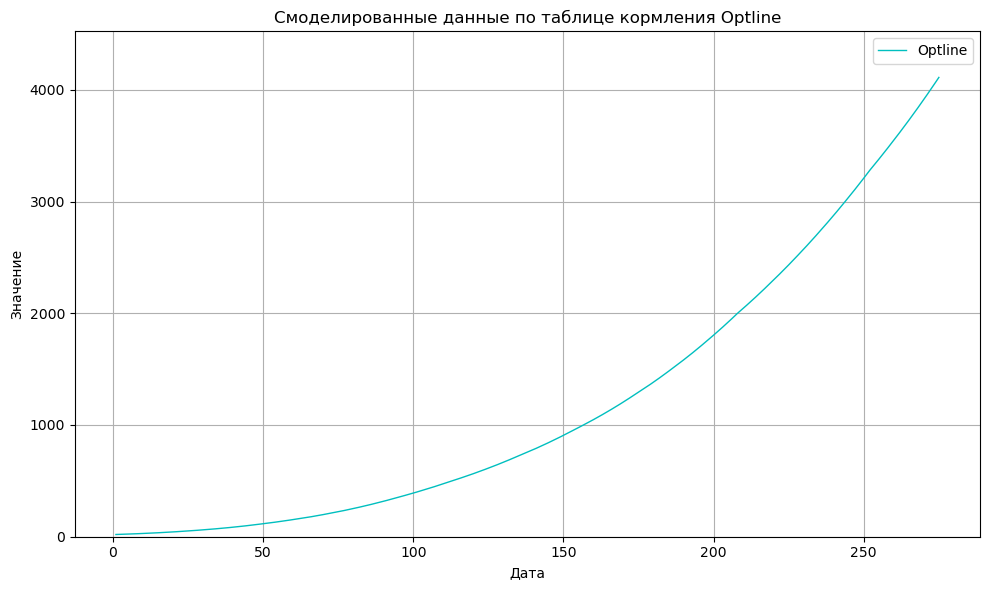

In [7]:
picture("Optline")

## Модели роста для сравнения

Для сравнения были выбраны несколько индивидуальных моделей роста.

1. Логистическая модель (LGM): $$W(t) = \dfrac{A}{1+e^{-k(t-T_i)}}.$$
2. Модель Гомперца (GGM): $$W(t) = A\cdot e^{-e^{-k(t-T_i)}}.$$
3. Модель фон Берталанфи (VBGM): $$W(t) = A\cdot \left(1-\frac{1}{3}\cdot e^{-k(t-T_i)}\right)^{3}.$$
4. Обобщенная модель Ричардса (RGM): $$W(t)=  A\cdot \left(1+(d-1)\cdot e^{\frac{-k(t-T_i)}{d^{d/(1-d)}}}\right)^{\frac{1}{1-d}}.$$

6. Модель Шнуте-Ричардса (CHRM): $$W(t) =  A\cdot \left(1+\delta\cdot e^{-kt^v}\right)^{\frac{1}{\gamma}}.$$

Основные обозначения: $W(t)$ - вес рыбы в момент времени $t$; $A$ - верхняя асимптота или максимальный вес взрослой рыбы; $k$ - константа скорости; $T_i$  - время в точке перегиба; $T_0$  - время, когда вес рыбы равен нулю; $d$, $\delta$, $v$, $\gamma$ - некоторые параметры.



In [8]:
# Mодель фон Берталанфи
def funcVBGM(x, A, k, T):
    """
    Модель фон Берталанфи для веса с защитой от численных ошибок.

    W(t) = A * (1 - (1/3) * exp(-k * (t - T)))^3

    Args:
      x:       Время (t) (скаляр или массив NumPy).
      A:       Асимптотический предел веса (W_infinity).
      k:       Коэффициент скорости роста.
      T:       Теоретический возраст при нулевом весе (t_0).

    Returns:
      W(t): Предсказанный вес.
    """
    
    # 1. Вычисляем аргумент экспоненты: -k * (x - T)
    # Ограничиваем его, чтобы избежать переполнения/исчезновения np.exp()
    exponent_arg = np.clip(-k * (x - T), -500, 500)
    
    # 2. Вычисляем внутреннюю часть скобки: 1 - (1/3) * exp(exponent_arg)
    # np.exp(exponent_arg) всегда будет положительным и конечным.
    inner_term = 1 - (1/3) * np.exp(exponent_arg)
    
    # 3. Защита от отрицательных значений внутри степени, если степень - дробная.
    # В данном случае степень = 3, что является целым числом, поэтому np.power()
    # корректно обрабатывает отрицательные числа.
    # Однако, в биологии вес не может быть отрицательным.
    # Поэтому мы обрезаем inner_term, чтобы избежать отрицательных весов.
    # Это гарантирует, что W(t) >= 0.
    inner_term_positive = np.maximum(0, inner_term)
    
    # 4. Возводим в степень 3 и умножаем на A
    return A * np.power(inner_term_positive, 3)


In [9]:
# Модель Гомперца
def funcGGM(x, A, k, T):
    """
    Модель Гомперца с защитой от численных ошибок.

    W(t) = A * exp(-exp(-k * (t - T)))

    Args:
      x:       Время (t) (скаляр или массив NumPy).
      A:       Асимптотический предел (максимальный вес/размер).
      k:       Коэффициент скорости роста.
      T:       Время (возраст) в точке перегиба (момент максимальной скорости роста).

    Returns:
      W(t): Предсказанный вес/размер.
    """
    # 1. Ограничиваем аргумент ВНУТРЕННЕЙ экспоненты (-k * (x - T))
    # Это критически важно, так как очень большое значение здесь приведет к exp(большое) -> inf,
    # а очень маленькое значение приведет к exp(малое) -> 0.0, что меняет дальнейшие расчеты.
    inner_exponent_arg = np.clip(-k * (x - T), -500, 500) 
    
    # 2. Вычисляем ВНУТРЕННЮЮ экспоненту
    exp_inner = np.exp(inner_exponent_arg)
    
    # 3. Ограничиваем аргумент ВНЕШНЕЙ экспоненты (-exp_inner)
    # exp_inner может быть большим, и тогда -exp_inner будет очень маленьким отрицательным числом.
    # np.clip здесь предотвращает, например, -inf, которое может возникнуть, если exp_inner уже был inf.
    outer_exponent_arg = np.clip(-exp_inner, -500, 500) 
    
    # 4. Вычисляем ВНЕШНЮЮ экспоненту
    exp_outer = np.exp(outer_exponent_arg)
    
    # 5. Итоговый результат
    return A * exp_outer

In [10]:
def funcLGM(x, A, k, T):
    """
    Логистическая модель роста с защитой от численных ошибок.

    W(t) = A / (1 + exp(-k * (t - T)))

    Args:
      x:       Время (t) (скаляр или массив NumPy).
      A:       Асимптотический предел (максимальный вес/размер).
      k:       Коэффициент скорости роста.
      T:       Время (возраст) в точке перегиба (максимальной скорости роста).

    Returns:
      W(t): Предсказанный вес/размер.
    """
    # 1. Ограничиваем аргумент экспоненты (-k * (x - T))
    # Это предотвращает переполнение (inf) или исчезновение (0.0) при больших/малых значениях.
    # Диапазон [-500, 500] обычно достаточен для большинства случаев.
    # np.clip возвращает значения в пределах min/max.
    exponent_arg = np.clip(-k * (x - T), -500, 500)
    
    # 2. Вычисляем знаменатель: 1 + exp(аргумент)
    # exp(exponent_arg) теперь гарантированно будет в пределах (0, exp(500)], что безопасно.
    denominator = 1 + np.exp(exponent_arg)
    
    # 3. Вычисляем итоговое значение W(t)
    # A / denominator. Убедимся, что знаменатель не равен нулю (хотя с exp он всегда > 1).
    return A / denominator

In [11]:
# Модель Ричарда
def funcRGM(x, A, k, T, d):
    """
    Обобщенная модель Ричардса с защитой от численных ошибок и особых случаев.

    W(t) = A * (1 + (d-1) * exp(-k*(t-T) / (d^(d/(1-d)))))^(1/(1-d))

    Args:
      x:       Время (t) (скаляр или массив NumPy).
      A:       Асимптотический предел.
      k:       Коэффициент скорости роста.
      T:       Теоретический возраст при нулевом размере (или точка перегиба).
      d:       Параметр формы, определяющий симметрию кривой.

    Returns:
      W(t): Предсказанный вес/размер.
    """
    
    # 1. Проверки для параметра 'd'
    # d не должно быть близко к 1 (иначе деление на 0)
    if np.isclose(d, 1.0):
        # Если d -> 1, модель Ричардса стремится к логистической.
        # Возвращаем NaN, т.к. эта формула не предназначена для d=1.
        # Для d=1 следует использовать funcLGM.
        return np.full_like(x, np.nan) 
    
    # d не должно быть близко к 0, т.к. оно используется как основание для степени d/(1-d)
    if np.isclose(d, 0.0):
        # Также может вызвать проблемы.
        return np.full_like(x, np.nan)

    # Защита от отрицательного основания для np.power(d, ...)
    # В модели Ричардса d часто полагается положительным.
    d_positive = np.maximum(1e-9, d) 

    # 2. Вычисление части (d^(d/(1-d)))
    power_d_exp = d_positive / (1 - d_positive)
    # Защита от переполнения/исчезновения при d_positive^power_d_exp
    # power_d_exp может быть большим
    d_raised_to_power = np.power(d_positive, np.clip(power_d_exp, -500, 500))
    # Защита от деления на ноль, если d_raised_to_power очень мало
    d_raised_to_power = np.maximum(1e-9, d_raised_to_power)
    
    # 3. Вычисление аргумента экспоненты: -k*(x-T) / (d^(d/(1-d)))
    exponent_arg_num = -k * (x - T)
    exponent_arg = exponent_arg_num / d_raised_to_power
    
    # Ограничиваем аргумент экспоненты для численной стабильности
    exponent_arg_clipped = np.clip(exponent_arg, -500, 500)
    
    # 4. Вычисление основания для финальной степени: 1 + (d-1)*exp(...)
    exp_val = np.exp(exponent_arg_clipped)
    base_value = 1 + (d_positive - 1) * exp_val
    
    # Защита от отрицательного основания, если 1/(1-d) - дробное число
    # (может дать комплексное или ошибку).
    # Физически, размер не может быть комплексным или нереальным.
    base_value = np.maximum(1e-9, base_value) 
    
    # 5. Вычисление финальной степени: 1 / (1-d)
    final_power = 1 / (1 - d_positive)
    
    # final_power может быть очень большим, если d близко к 1. 
    # В таких случаях np.power может выдать inf/0.
    # Если это происходит часто, возможно, следует рассмотреть другую параметризацию
    # или дополнительно клиповать final_power, но это может исказить форму.
    # Для большинства случаев это не требуется, если d_positive не слишком близко к 1.

    # 6. Итоговый результат
    return A * np.power(base_value, final_power)

In [12]:
# Модель Шнутте
def funcSGM(x, A, k, delta, nu, gamma):
    """
  Вычисляет W(t) по формуле: W(t) = A * (1 + delta * exp(-k*t^nu))**(1/gamma)

  Args:
    x:  Время (может быть скаляром или массивом NumPy).
    A:  Асимптотический предел (скаляр).
    delta:Параметр формы (скаляр).
    k: Коэффициент скорости роста (скаляр).
    nu: Параметр nu (скаляр).
    gamma: Параметр gamma (скаляр).

  Returns:
    W(t): Значение W(t) для заданного времени t (скаляр или массив NumPy, в зависимости от типа t).
  """
    # 1. Проверки на входные параметры и численную устойчивость
    # Защита от деления на ноль, если gamma очень близко к 0
    if np.isclose(gamma, 0): # np.isclose() лучше для сравнения float с 0
        return np.full_like(x, np.nan) 
    
    # Возраст (x) не должен быть отрицательным для x**nu
    # Если x может быть отрицательным, то (x**nu) будет нереальным
    x_positive = np.maximum(1e-9, x) # Гарантируем x > 0 для возведения в степень
    
    # 2. Вычисление внутренней части (аргумент экспоненты)
    # x_positive**nu может быть очень большим или очень малым, если nu большое
    # Ограничиваем x_positive**nu, если nu очень большое
    x_power_nu = np.power(x_positive, nu)
    
    # Аргумент экспоненты: -k * x^nu
    # Ограничиваем его для численной стабильности, чтобы np.exp не вернул inf/0
    exponent_arg = np.clip(-k * x_power_nu, -500, 500) 
    
    # 3. Вычисление основания для финальной степени
    base_value = 1 + delta * np.exp(exponent_arg)
    
    # Защита от отрицательного основания, если gamma - дробное число (может дать комплексное)
    # или если основание становится слишком близким к нулю
    base_value = np.maximum(1e-9, base_value) 
    
    # 4. Вычисление финального результата
    power_exponent = 1 / gamma
    
    # Если power_exponent очень большое (gamma очень близко к 0),
    # np.power может выдать inf/0. Но мы уже проверили gamma=0.
    # Дополнительная защита:
    # power_exponent = np.clip(power_exponent, -500, 500) # Может быть нужно в экстремальных случаях
    
    return A * np.power(base_value, power_exponent)
    # return  A * (1 + delta * np.exp(-k * (x**nu)))**(1/gamma)

Все введенные функции зависят от двух или трех параметров, поэтому заранее введем для них переменные:

## 1. Подбор коэффициентов для соответствия моделей роста набору данных

In [13]:
# Наблюдаемые данные
xdata=np.array(data_all['date'])
ydata=np.array(data_all['data'])

Функция для поиска оптимальных коэффициентов нелинейных моделей роста

In [14]:
def optimizator(function, xdata, ydata, p0=None, bounds=(-np.inf, np.inf), method='lm', maxfev=None, **kwargs):
    """
    Оптимизирует параметры модели роста, используя curve_fit.

    Args:
        function: Модель роста (функция).
        xdata: Временной промежуток роста.
        ydata: Данные о весе в каждый момент времени из xdata.
        p0: Начальные значения параметров (опционально).
        bounds: Границы для параметров (опционально).  Может быть кортежем (min, max) для всех параметров
                или последовательностью кортежей для каждого параметра.
        method: Метод оптимизации (см. документацию scipy.optimize.curve_fit).
        maxfev: Максимальное количество вычислений функции (maxfev в curve_fit).
        **kwargs: Дополнительные аргументы, передаваемые в curve_fit.

    Returns:
        params: Оптимальные параметры.
        pcov: Ковариационная матрица параметров.
        message: Сообщение об успехе или неудаче (None, если все прошло успешно).

    Raises:
        ValueError: Если xdata и ydata имеют разную длину.
        RuntimeError: Если curve_fit не смог сойтись.
    """
    if len(xdata) != len(ydata):
        raise ValueError("xdata и ydata должны иметь одинаковую длину.")

    try:
        params, pcov = curve_fit(function, xdata, ydata, p0=p0, bounds=bounds, method=method, maxfev=maxfev, full_output=False, **kwargs) # full_output=True даст infodict
        message = None # Сообщение об успехе
        return params, pcov, message

    except RuntimeError as e:
        return None, None, str(e) # Возвращаем строку ошибки
    except Exception as e:  # Ловим другие возможные исключения
        return None, None, f"Произошла ошибка: {str(e)}" # Сообщение о другой ошибке

- Поиск оптимальных параметров для логистической модели (LGM)

In [15]:
bounds = ([np.max(ydata), 1e-5, np.min(xdata)], [np.max(ydata)*3, 0.1,  np.max(xdata)*2])
num_iterations = 1000 # Количество случайных запусков
best_rmse = np.inf   # Инициализируем лучшую RMSE очень большим числом
best_params = None   # Здесь будут храниться лучшие параметры
best_pcov = None     # Ковариационная матрица для лучших параметров
best_message = ""    # Сообщение об успешной оптимизации для лучшего результата

# Функция-обертка для least_squares, чтобы ее можно было использовать как curve_fit
# (least_squares ожидает функцию, возвращающую массив остатков, а не предсказаний)
def residuals_func(params, x, y_true, model_func):
    return y_true - model_func(x, *params)

# --- 3. Цикл оптимизации ---

print(f"Запуск {num_iterations} итераций оптимизации...")
for i in range(num_iterations):
    # Генерация случайных начальных параметров в пределах bounds
    A_start = np.random.uniform(bounds[0][0], bounds[1][0])
    k_start = np.random.uniform(bounds[0][1], bounds[1][1])
    T_start = np.random.uniform(bounds[0][2], bounds[1][2])
    p0 = [A_start, k_start, T_start]

    try:
        # Используем least_squares напрямую, так как он лучше поддерживает bounds
        # и method='trf'
        res = least_squares(
            residuals_func, # Функция, возвращающая остатки
            p0,             # Начальные параметры
            args=(xdata, ydata, funcLGM), # Дополнительные аргументы для residuals_func
            bounds=bounds,
            method='trf',
            max_nfev=5000, # Увеличим max_nfev (в least_squares это max_nfev, не maxfev)
            ftol=1e-8,      # Толерантность по ошибке (уменьшаем для большей точности)
            xtol=1e-8       # Толерантность по параметрам
        )

        # res.x - найденные параметры
        # res.cost - половина суммы квадратов остатков: 0.5 * sum(residuals**2)
        # res.fun - массив остатков

        current_params = res.x
        
        # Предсказания модели с текущими параметрами
        y_predicted = funcLGM(xdata, *current_params)
        
        # Расчет RMSE
        current_rmse = np.sqrt(mean_squared_error(ydata, y_predicted))

        # Проверка, является ли текущий результат лучшим
        if current_rmse < best_rmse:
            best_rmse = current_rmse
            best_params = current_params
            
            # pcov в least_squares нужно вычислять отдельно
            # Если Jacobian (res.jac) не сингулярна
            if res.jac.shape[0] >= res.jac.shape[1] and np.linalg.det(res.jac.T @ res.jac) != 0:
                 best_pcov = np.linalg.inv(res.jac.T @ res.jac) * res.cost * 2 / (len(ydata) - len(p0))
            else:
                 best_pcov = np.full((len(p0), len(p0)), np.nan) # Если не удалось вычислить pcov

            best_message = res.message
            print(f"  Итерация {i+1}: Найден новый лучший RMSE = {best_rmse:.4f}")

    except Exception as e:
        # Можно вывести ошибку, но не останавливать весь цикл
        # print(f"  Итерация {i+1}: Ошибка оптимизации: {e}")
        pass # Просто пропускаем итерации с ошибками

# --- 4. Вывод наилучших результатов ---

if best_params is not None:
    A_LGM, k_LGM, T_LGM = best_params
    print("\n--- Наилучшие результаты ---")
    print(f"Наилучший RMSE: {best_rmse:.4f}")
    print(f"Наилучшие параметры: A = {A_LGM:.4f}, k = {k_LGM:.8f}, T = {T_LGM:.4f}.")
    print(f"Сообщение оптимизатора: {best_message}")

    # Вычисление стандартных ошибок
    if best_pcov is not None and not np.all(np.isnan(best_pcov)):
        perr = np.sqrt(np.diag(best_pcov))
        print("\nСтандартные ошибки параметров:")
        param_names = ['A', 'k', 'T']
        for i, error_val in enumerate(perr):
            print(f"  {param_names[i]}: {error_val:.8f}")
    else:
        print("\nКовариационная матрица (pcov) не была успешно вычислена или содержит NaN.")
else:
    print("Оптимизация не дала ни одного успешного результата.")



Запуск 1000 итераций оптимизации...
  Итерация 1: Найден новый лучший RMSE = 34.2548
  Итерация 2: Найден новый лучший RMSE = 34.2548
  Итерация 3: Найден новый лучший RMSE = 34.2548
  Итерация 8: Найден новый лучший RMSE = 34.2548
  Итерация 13: Найден новый лучший RMSE = 34.2548
  Итерация 18: Найден новый лучший RMSE = 34.2548
  Итерация 24: Найден новый лучший RMSE = 34.2548
  Итерация 27: Найден новый лучший RMSE = 34.2548
  Итерация 72: Найден новый лучший RMSE = 34.2548
  Итерация 73: Найден новый лучший RMSE = 34.2548
  Итерация 83: Найден новый лучший RMSE = 34.2548
  Итерация 189: Найден новый лучший RMSE = 34.2548
  Итерация 203: Найден новый лучший RMSE = 34.2548

--- Наилучшие результаты ---
Наилучший RMSE: 34.2548
Наилучшие параметры: A = 7366.1574, k = 0.01760432, delta = 264.0916.
Сообщение оптимизатора: `ftol` termination condition is satisfied.

Стандартные ошибки параметров:
  A: 120.15445569
  k: 0.00012421
  T: 1.75034313


In [16]:
# perr = np.sqrt(np.diag(pcov))
# formatted_errors = [f"{val:8f}" for val in perr]
# print(f"Cтандартные ошибки параметров модели LGM [{','.join(formatted_errors)}]")
# print()

# diag_std = np.sqrt(np.diag(pcov))
# corr_matrix = pcov / np.outer(diag_std, diag_std)

# print(f"Корелляционная матрица модели LGM ")
# corr_matrix

- Поиск оптимальных параметров для Модели Гомперца (GGM)

In [17]:
bounds = ([np.max(ydata), 1e-5, np.min(xdata)], [np.max(ydata)*3, 0.1,  np.max(xdata)*2])
num_iterations = 1000 # Количество случайных запусков
best_rmse = np.inf   # Инициализируем лучшую RMSE очень большим числом
best_params = None   # Здесь будут храниться лучшие параметры
best_pcov = None     # Ковариационная матрица для лучших параметров
best_message = ""    # Сообщение об успешной оптимизации для лучшего результата

# Функция-обертка для least_squares, чтобы ее можно было использовать как curve_fit
# (least_squares ожидает функцию, возвращающую массив остатков, а не предсказаний)
def residuals_func(params, x, y_true, model_func):
    return y_true - model_func(x, *params)

# --- 3. Цикл оптимизации ---

print(f"Запуск {num_iterations} итераций оптимизации...")
for i in range(num_iterations):
    # Генерация случайных начальных параметров в пределах bounds
    A_start = np.random.uniform(bounds[0][0], bounds[1][0])
    k_start = np.random.uniform(bounds[0][1], bounds[1][1])
    T_start = np.random.uniform(bounds[0][2], bounds[1][2])
    p0 = [A_start, k_start, T_start]

    try:
        # Используем least_squares напрямую, так как он лучше поддерживает bounds
        # и method='trf'
        res = least_squares(
            residuals_func, # Функция, возвращающая остатки
            p0,             # Начальные параметры
            args=(xdata, ydata, funcGGM), # Дополнительные аргументы для residuals_func
            bounds=bounds,
            method='trf',
            max_nfev=5000, # Увеличим max_nfev (в least_squares это max_nfev, не maxfev)
            ftol=1e-8,      # Толерантность по ошибке (уменьшаем для большей точности)
            xtol=1e-8       # Толерантность по параметрам
        )

        # res.x - найденные параметры
        # res.cost - половина суммы квадратов остатков: 0.5 * sum(residuals**2)
        # res.fun - массив остатков

        current_params = res.x
        
        # Предсказания модели с текущими параметрами
        y_predicted = funcGGM(xdata, *current_params)
        
        # Расчет RMSE
        current_rmse = np.sqrt(mean_squared_error(ydata, y_predicted))

        # Проверка, является ли текущий результат лучшим
        if current_rmse < best_rmse:
            best_rmse = current_rmse
            best_params = current_params
            
            # pcov в least_squares нужно вычислять отдельно
            # Если Jacobian (res.jac) не сингулярна
            if res.jac.shape[0] >= res.jac.shape[1] and np.linalg.det(res.jac.T @ res.jac) != 0:
                 best_pcov = np.linalg.inv(res.jac.T @ res.jac) * res.cost * 2 / (len(ydata) - len(p0))
            else:
                 best_pcov = np.full((len(p0), len(p0)), np.nan) # Если не удалось вычислить pcov

            best_message = res.message
            print(f"  Итерация {i+1}: Найден новый лучший RMSE = {best_rmse:.4f}")

    except Exception as e:
        # Можно вывести ошибку, но не останавливать весь цикл
        # print(f"  Итерация {i+1}: Ошибка оптимизации: {e}")
        pass # Просто пропускаем итерации с ошибками

# --- 4. Вывод наилучших результатов ---

if best_params is not None:
    A_GGM, k_GGM, T_GGM = best_params
    print("\n--- Наилучшие результаты ---")
    print(f"Наилучший RMSE: {best_rmse:.4f}")
    print(f"Наилучшие параметры: A = {A_GGM:.4f}, k = {k_GGM:.8f}, T = {T_GGM:.4f}.")
    print(f"Сообщение оптимизатора: {best_message}")

    # Вычисление стандартных ошибок
    if best_pcov is not None and not np.all(np.isnan(best_pcov)):
        perr = np.sqrt(np.diag(best_pcov))
        print("\nСтандартные ошибки параметров:")
        param_names = ['A', 'k', 'T']
        for i, error_val in enumerate(perr):
            print(f"  {param_names[i]}: {error_val:.8f}")
    else:
        print("\nКовариационная матрица (pcov) не была успешно вычислена или содержит NaN.")
else:
    print("Оптимизация не дала ни одного успешного результата.")



Запуск 1000 итераций оптимизации...
  Итерация 1: Найден новый лучший RMSE = 57.5727
  Итерация 4: Найден новый лучший RMSE = 57.5727
  Итерация 5: Найден новый лучший RMSE = 57.5727
  Итерация 10: Найден новый лучший RMSE = 57.5727
  Итерация 28: Найден новый лучший RMSE = 57.5727
  Итерация 37: Найден новый лучший RMSE = 57.5727
  Итерация 77: Найден новый лучший RMSE = 57.5727
  Итерация 101: Найден новый лучший RMSE = 57.5727
  Итерация 153: Найден новый лучший RMSE = 57.5727
  Итерация 474: Найден новый лучший RMSE = 57.5727

--- Наилучшие результаты ---
Наилучший RMSE: 57.5727
Наилучшие параметры: A = 12331.7508, k = 0.00661454, delta = 295.5976.
Сообщение оптимизатора: `ftol` termination condition is satisfied.

Стандартные ошибки параметров:
  A: 592.76286384
  k: 0.00017284
  T: 6.52724055


- Поиск оптимальных параметров для Модели фон Берталанфи (VBGM)

In [23]:
bounds = ([np.max(ydata), 1e-5, np.min(xdata)], [np.max(ydata)*3, 0.1,  np.max(xdata)*2])
num_iterations = 1000 # Количество случайных запусков
best_rmse = np.inf   # Инициализируем лучшую RMSE очень большим числом
best_params = None   # Здесь будут храниться лучшие параметры
best_pcov = None     # Ковариационная матрица для лучших параметров
best_message = ""    # Сообщение об успешной оптимизации для лучшего результата

# Функция-обертка для least_squares, чтобы ее можно было использовать как curve_fit
# (least_squares ожидает функцию, возвращающую массив остатков, а не предсказаний)
def residuals_func(params, x, y_true, model_func):
    return y_true - model_func(x, *params)

# --- 3. Цикл оптимизации ---

print(f"Запуск {num_iterations} итераций оптимизации...")
for i in range(num_iterations):
    # Генерация случайных начальных параметров в пределах bounds
    A_start = np.random.uniform(bounds[0][0], bounds[1][0])
    k_start = np.random.uniform(bounds[0][1], bounds[1][1])
    T_start = np.random.uniform(bounds[0][2], bounds[1][2])
    p0 = [A_start, k_start, T_start]

    try:
        # Используем least_squares напрямую, так как он лучше поддерживает bounds
        # и method='trf'
        res = least_squares(
            residuals_func, # Функция, возвращающая остатки
            p0,             # Начальные параметры
            args=(xdata, ydata, funcVBGM), # Дополнительные аргументы для residuals_func
            bounds=bounds,
            method='trf',
            max_nfev=5000, # Увеличим max_nfev (в least_squares это max_nfev, не maxfev)
            ftol=1e-8,      # Толерантность по ошибке (уменьшаем для большей точности)
            xtol=1e-8       # Толерантность по параметрам
        )

        # res.x - найденные параметры
        # res.cost - половина суммы квадратов остатков: 0.5 * sum(residuals**2)
        # res.fun - массив остатков

        current_params = res.x
        
        # Предсказания модели с текущими параметрами
        y_predicted = funcVBGM(xdata, *current_params)
        
        # Расчет RMSE
        current_rmse = np.sqrt(mean_squared_error(ydata, y_predicted))

        # Проверка, является ли текущий результат лучшим
        if current_rmse < best_rmse:
            best_rmse = current_rmse
            best_params = current_params
            
            # pcov в least_squares нужно вычислять отдельно
            # Если Jacobian (res.jac) не сингулярна
            if res.jac.shape[0] >= res.jac.shape[1] and np.linalg.det(res.jac.T @ res.jac) != 0:
                 best_pcov = np.linalg.inv(res.jac.T @ res.jac) * res.cost * 2 / (len(ydata) - len(p0))
            else:
                 best_pcov = np.full((len(p0), len(p0)), np.nan) # Если не удалось вычислить pcov

            best_message = res.message
            print(f"  Итерация {i+1}: Найден новый лучший RMSE = {best_rmse:.4f}")

    except Exception as e:
        # Можно вывести ошибку, но не останавливать весь цикл
        # print(f"  Итерация {i+1}: Ошибка оптимизации: {e}")
        pass # Просто пропускаем итерации с ошибками

# --- 4. Вывод наилучших результатов ---

if best_params is not None:
    A_VBGM, k_VBGM, T_VBGM = best_params
    print("\n--- Наилучшие результаты ---")
    print(f"Наилучший RMSE: {best_rmse:.4f}")
    print(f"Наилучшие параметры: A = {A_VBGM:.4f}, k = {k_VBGM:.8f}, T = {T_VBGM:.4f}.")
    print(f"Сообщение оптимизатора: {best_message}")

    # Вычисление стандартных ошибок
    if best_pcov is not None and not np.all(np.isnan(best_pcov)):
        perr = np.sqrt(np.diag(best_pcov))
        print("\nСтандартные ошибки параметров:")
        param_names = ['A', 'k', 'T']
        for i, error_val in enumerate(perr):
            print(f"  {param_names[i]}: {error_val:.8f}")
    else:
        print("\nКовариационная матрица (pcov) не была успешно вычислена или содержит NaN.")
else:
    print("Оптимизация не дала ни одного успешного результата.")



Запуск 1000 итераций оптимизации...
  Итерация 1: Найден новый лучший RMSE = 1669.2718
  Итерация 2: Найден новый лучший RMSE = 114.7527
  Итерация 20: Найден новый лучший RMSE = 114.7527
  Итерация 26: Найден новый лучший RMSE = 114.7527
  Итерация 41: Найден новый лучший RMSE = 114.7527
  Итерация 122: Найден новый лучший RMSE = 114.7527
  Итерация 280: Найден новый лучший RMSE = 114.7527

--- Наилучшие результаты ---
Наилучший RMSE: 114.7527
Наилучшие параметры: A = 12331.7508, k = 0.00460285, T = 269.8848.
Сообщение оптимизатора: `ftol` termination condition is satisfied.

Стандартные ошибки параметров:
  A: 1329.46859046
  k: 0.00035746
  T: 14.98529347


- Поиск оптимальных параметров для Модели Ричардса (RGM)

In [25]:
# Параметры A, k, T, delta
bounds = ([np.max(ydata), 1e-5, np.min(xdata), 0.01], [np.max(ydata)*3, 0.1, np.max(xdata)*2, 5])
num_iterations = 1000 # Количество случайных запусков
best_rmse = np.inf   # Инициализируем лучшую RMSE очень большим числом
best_params = None   # Здесь будут храниться лучшие параметры
best_pcov = None     # Ковариационная матрица для лучших параметров
best_message = ""    # Сообщение об успешной оптимизации для лучшего результата

# Функция-обертка для least_squares, чтобы ее можно было использовать как curve_fit
# (least_squares ожидает функцию, возвращающую массив остатков, а не предсказаний)
def residuals_func(params, x, y_true, model_func):
    return y_true - model_func(x, *params)

# --- 3. Цикл оптимизации ---

print(f"Запуск {num_iterations} итераций оптимизации...")
for i in range(num_iterations):
    # Генерация случайных начальных параметров в пределах bounds
    A_start = np.random.uniform(bounds[0][0], bounds[1][0])
    k_start = np.random.uniform(bounds[0][1], bounds[1][1])
    T_start = np.random.uniform(bounds[0][2], bounds[1][2])
    delta_start = np.random.uniform(bounds[0][3], bounds[1][3])

    p0 = [A_start, k_start, T_start, delta_start]

    try:
        # Используем least_squares напрямую, так как он лучше поддерживает bounds
        # и method='trf'
        res = least_squares(
            residuals_func, # Функция, возвращающая остатки
            p0,             # Начальные параметры
            args=(xdata, ydata, funcRGM), # Дополнительные аргументы для residuals_func
            bounds=bounds,
            method='trf',
            max_nfev=5000, # Увеличим max_nfev (в least_squares это max_nfev, не maxfev)
            ftol=1e-8,      # Толерантность по ошибке (уменьшаем для большей точности)
            xtol=1e-8       # Толерантность по параметрам
        )

        # res.x - найденные параметры
        # res.cost - половина суммы квадратов остатков: 0.5 * sum(residuals**2)
        # res.fun - массив остатков

        current_params = res.x
        
        # Предсказания модели с текущими параметрами
        y_predicted = funcRGM(xdata, *current_params)
        
        # Расчет RMSE
        current_rmse = np.sqrt(mean_squared_error(ydata, y_predicted))

        # Проверка, является ли текущий результат лучшим
        if current_rmse < best_rmse:
            best_rmse = current_rmse
            best_params = current_params
            
            # pcov в least_squares нужно вычислять отдельно
            # Если Jacobian (res.jac) не сингулярна
            if res.jac.shape[0] >= res.jac.shape[1] and np.linalg.det(res.jac.T @ res.jac) != 0:
                 best_pcov = np.linalg.inv(res.jac.T @ res.jac) * res.cost * 2 / (len(ydata) - len(p0))
            else:
                 best_pcov = np.full((len(p0), len(p0)), np.nan) # Если не удалось вычислить pcov

            best_message = res.message
            print(f"  Итерация {i+1}: Найден новый лучший RMSE = {best_rmse:.4f}")

    except Exception as e:
        # Можно вывести ошибку, но не останавливать весь цикл
        # print(f"  Итерация {i+1}: Ошибка оптимизации: {e}")
        pass # Просто пропускаем итерации с ошибками

# --- 4. Вывод наилучших результатов ---

if best_params is not None:
    A_RGM, k_RGM, T_RGM, d_RGM= best_params
    print("\n--- Наилучшие результаты ---")
    print(f"Наилучший RMSE: {best_rmse:.4f}")
    print(f"Наилучшие параметры: A = {A_RGM:.4f}, k = {k_RGM:.8f}, T = {T_RGM:.4f}, delta = {d_RGM:.4f}.")
    print(f"Сообщение оптимизатора: {best_message}")

    # Вычисление стандартных ошибок
    if best_pcov is not None and not np.all(np.isnan(best_pcov)):
        perr = np.sqrt(np.diag(best_pcov))
        print("\nСтандартные ошибки параметров:")
        param_names = ['A', 'k', 'T', 'delta']
        for i, error_val in enumerate(perr):
            print(f"  {param_names[i]}: {error_val:.8f}")
    else:
        print("\nКовариационная матрица (pcov) не была успешно вычислена или содержит NaN.")
else:
    print("Оптимизация не дала ни одного успешного результата.")



Запуск 1000 итераций оптимизации...
  Итерация 1: Найден новый лучший RMSE = 22.1826
  Итерация 3: Найден новый лучший RMSE = 22.1826
  Итерация 38: Найден новый лучший RMSE = 22.1826
  Итерация 58: Найден новый лучший RMSE = 22.1826
  Итерация 153: Найден новый лучший RMSE = 22.1826
  Итерация 365: Найден новый лучший RMSE = 22.1826


C:\Users\Elena\anaconda3\Lib\site-packages\numpy\_core\numeric.py:457: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')



--- Наилучшие результаты ---
Наилучший RMSE: 22.1826
Наилучшие параметры: A = 12331.7508, k = 0.00294556, T = 309.3736, delta = 1.3814.
Сообщение оптимизатора: `xtol` termination condition is satisfied.

Стандартные ошибки параметров:
  A: 999.74321043
  k: 0.00015713
  T: 8.72390243
  delta: 0.05008831


- Поиск оптимальных параметров для Модели Шнутте-Ричардса (SGM)

In [20]:
bounds = ([np.max(ydata), 1e-5, 0.01, 0.1,-10], [np.max(ydata)*3, 0.1, 10, 4.0, 10]) 
num_iterations = 1000 # Количество случайных запусков
best_rmse = np.inf   # Инициализируем лучшую RMSE очень большим числом
best_params = None   # Здесь будут храниться лучшие параметры
best_pcov = None     # Ковариационная матрица для лучших параметров
best_message = ""    # Сообщение об успешной оптимизации для лучшего результата

# Функция-обертка для least_squares, чтобы ее можно было использовать как curve_fit
# (least_squares ожидает функцию, возвращающую массив остатков, а не предсказаний)
def residuals_func(params, x, y_true, model_func):
    return y_true - model_func(x, *params)

# --- 3. Цикл оптимизации ---

print(f"Запуск {num_iterations} итераций оптимизации...")
for i in range(num_iterations):
    # Генерация случайных начальных параметров в пределах bounds
    A_start = np.random.uniform(bounds[0][0], bounds[1][0])
    k_start = np.random.uniform(bounds[0][1], bounds[1][1])
    delta_start = np.random.uniform(bounds[0][2], bounds[1][2])
    nu_start = np.random.uniform(bounds[0][3], bounds[1][3])
    gamma_start = np.random.uniform(bounds[0][4], bounds[1][4])
    p0 = [A_start, k_start, delta_start, nu_start, gamma_start]

    try:
        # Используем least_squares напрямую, так как он лучше поддерживает bounds
        # и method='trf'
        res = least_squares(
            residuals_func, # Функция, возвращающая остатки
            p0,             # Начальные параметры
            args=(xdata, ydata, funcSGM), # Дополнительные аргументы для residuals_func
            bounds=bounds,
            method='trf',
            max_nfev=5000, # Увеличим max_nfev (в least_squares это max_nfev, не maxfev)
            ftol=1e-8,      # Толерантность по ошибке (уменьшаем для большей точности)
            xtol=1e-8       # Толерантность по параметрам
        )

        # res.x - найденные параметры
        # res.cost - половина суммы квадратов остатков: 0.5 * sum(residuals**2)
        # res.fun - массив остатков

        current_params = res.x
        
        # Предсказания модели с текущими параметрами
        y_predicted = funcSGM(xdata, *current_params)
        
        # Расчет RMSE
        current_rmse = np.sqrt(mean_squared_error(ydata, y_predicted))

        # Проверка, является ли текущий результат лучшим
        if current_rmse < best_rmse:
            best_rmse = current_rmse
            best_params = current_params
            
            # pcov в least_squares нужно вычислять отдельно
            # Если Jacobian (res.jac) не сингулярна
            if res.jac.shape[0] >= res.jac.shape[1] and np.linalg.det(res.jac.T @ res.jac) != 0:
                 best_pcov = np.linalg.inv(res.jac.T @ res.jac) * res.cost * 2 / (len(ydata) - len(p0))
            else:
                 best_pcov = np.full((len(p0), len(p0)), np.nan) # Если не удалось вычислить pcov

            best_message = res.message
            print(f"  Итерация {i+1}: Найден новый лучший RMSE = {best_rmse:.4f}")

    except Exception as e:
        # Можно вывести ошибку, но не останавливать весь цикл
        # print(f"  Итерация {i+1}: Ошибка оптимизации: {e}")
        pass # Просто пропускаем итерации с ошибками

# --- 4. Вывод наилучших результатов ---

if best_params is not None:
    A_SGM, k_SGM, d_SGM, nu_SGM, gamma_SGM = best_params
    print("\n--- Наилучшие результаты ---")
    print(f"Наилучший RMSE: {best_rmse:.4f}")
    print(f"Наилучшие параметры: A = {A_SGM:.4f}, k = {k_SGM:.8f}, delta = {d_SGM:.4f}, nu = {nu_SGM:.4f}, gamma = {gamma_SGM:.4f}.")
    print(f"Сообщение оптимизатора: {best_message}")

    # Вычисление стандартных ошибок
    if best_pcov is not None and not np.all(np.isnan(best_pcov)):
        perr = np.sqrt(np.diag(best_pcov))
        print("\nСтандартные ошибки параметров:")
        param_names = ['A', 'k', 'delta', 'nu', 'gamma']
        for i, error_val in enumerate(perr):
            print(f"  {param_names[i]}: {error_val:.8f}")
    else:
        print("\nКовариационная матрица (pcov) не была успешно вычислена или содержит NaN.")
else:
    print("Оптимизация не дала ни одного успешного результата.")



Запуск 1000 итераций оптимизации...
  Итерация 1: Найден новый лучший RMSE = 23.9733
  Итерация 163: Найден новый лучший RMSE = 22.8427
  Итерация 243: Найден новый лучший RMSE = 21.4874


C:\Users\Elena\AppData\Local\Temp\ipykernel_22784\1866622944.py:50: RuntimeWarning: overflow encountered in power
  return A * np.power(base_value, power_exponent)
C:\Users\Elena\AppData\Local\Temp\ipykernel_22784\1866622944.py:50: RuntimeWarning: overflow encountered in power
  return A * np.power(base_value, power_exponent)



--- Наилучшие результаты ---
Наилучший RMSE: 21.4874
Наилучшие параметры: A = 12181.1143, k = 0.01325298, delta = 9.9983, nu = 0.9538, gamma = -0.4275.
Сообщение оптимизатора: `xtol` termination condition is satisfied.

Стандартные ошибки параметров:
  A: 1629.93515681
  k: 0.01015636
  delta: 11.64154522
  nu: 0.09038140
  gamma: 0.19033543


Теперь построим полученные функции. Для этого создадим списки прогнозных значений

In [27]:
# Используем векторизацию NumPy для применения функций к массиву xdata
yLGM_predicted = np.round(funcLGM(xdata, A_LGM, k_LGM, T_LGM), 4)
yGGM_predicted = np.round(funcGGM(xdata, A_GGM, k_GGM, T_GGM), 4)
yVBGM_predicted = np.round(funcVBGM(xdata, A_VBGM, k_VBGM, T_VBGM), 4)
yRGM_predicted = np.round(funcRGM(xdata, A_RGM, k_RGM, T_RGM, d_RGM), 4)
ySGM_predicted = np.round(funcSGM(xdata, A_SGM, k_SGM, d_SGM, nu_SGM, gamma_SGM),5)

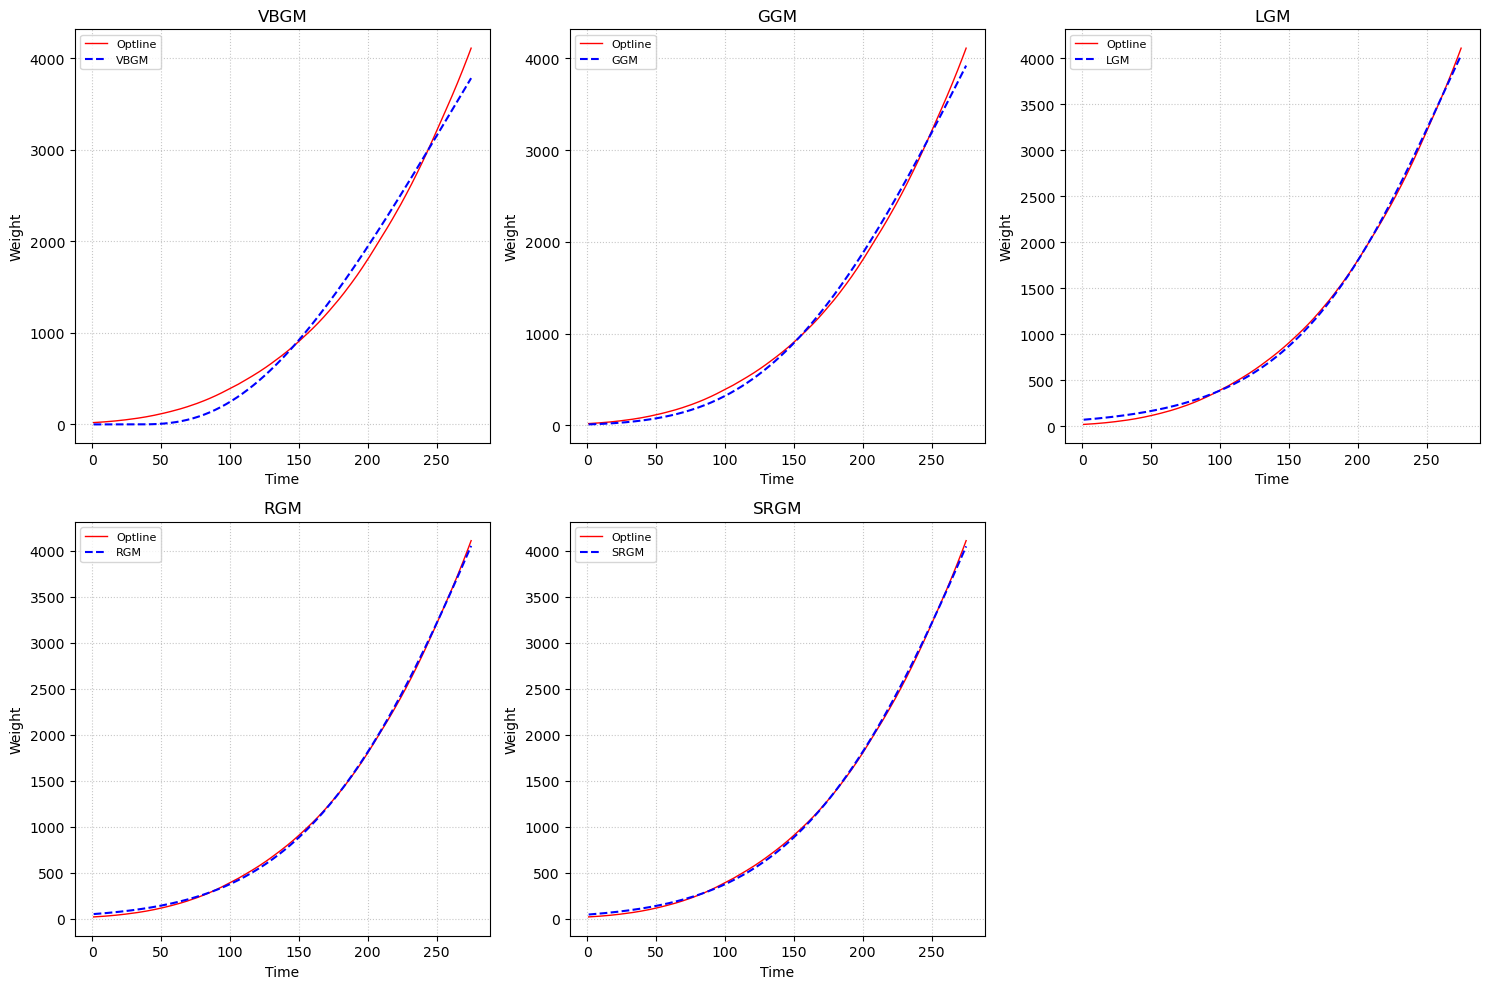

In [28]:
# --- 1. Создаем фигуру с сеткой 2x3
fig, axs = plt.subplots(2, 3, figsize=(15, 10)) # figsize (ширина, высота)

# Удаляем (скрываем) последний, неиспользуемый подграфик во второй строке.
# Это гарантирует, что на итоговой картинке его не будет.
fig.delaxes(axs[1, 2])

# Создаем список всех осей, которые мы будем использовать (их всего 5)
all_axes = [axs[0, 0], axs[0, 1], axs[0, 2], axs[1, 0], axs[1, 1]]

# Создаем списки предсказанных данных и их заголовков для удобства
predictions_list = [yVBGM_predicted, yGGM_predicted, yLGM_predicted, yRGM_predicted, ySGM_predicted]
titles_list = ['VBGM', 'GGM', 'LGM', 'RGM', 'SRGM']


# --- 3. Построение графиков в цикле ---

for i, ax in enumerate(all_axes):
    # Фактические данные
    ax.plot(xdata, ydata, color="red", label="Optline", linewidth=1.0, linestyle='-')
    
    # Предсказанные данные для текущей модели
    ax.plot(xdata, predictions_list[i], color='blue', label=titles_list[i], linewidth=1.5, linestyle='--')
    
    # Настройки для каждого подграфика
    ax.set_title(titles_list[i], fontsize=12)
    ax.legend(fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.7)
    
    # Общие подписи осей, если нужны на каждом графике
    ax.set_xlabel('Time', fontsize=10)
    ax.set_ylabel('Weight', fontsize=10)

# --- 4. Финальные настройки и отображение ---

# Автоматически регулирует параметры подграфиков, чтобы они умещались в области рисунка
# и не перекрывались. Это также помогает центрировать нижние два графика.
plt.tight_layout()

# Если нужно сохранить в файл:
plt.savefig('model_growth_trf.jpg')
# Показать графики
plt.show()

**Эффективность подгонки моделей**

**Критерий эффективности: среднеквадратичная ошибка Mean Squared Error (MSE)**

$MSE=\dfrac{1}{n}\sum\limits_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2$, $n$ - объем данных, $y_i$ - исходные данные, $\hat{y}_i$ - прогнозируемые данные

In [29]:
models = ["LGM", "GGM", "VBGM", "RGM", "SGM"]
predicts = [yLGM_predicted, yGGM_predicted, yVBGM_predicted, yRGM_predicted, ySGM_predicted]

MSE_dict = {}

for model, predict in zip(models, predicts):
    MSE_dict[model] = round(mean_squared_error(ydata, predict),2)

# # Вывод всех оценок
print(f'Значение MSE для каждой модели')
for key, value in MSE_dict.items():
    print(f"MSE для модели {key} равно {value}")

# Поиск лучшей оценки MSE и ее вывод
min_key, min_value = min(MSE_dict.items(), key=lambda x: x[1])
print(f"Лучшее MSE дает модель {min_key} со значением: {min_value}")

grades_dict = {}
grades_dict['MSE'] = [min_key, min_value]

Значение MSE для каждой модели
MSE для модели LGM равно 1173.39
MSE для модели GGM равно 3314.62
MSE для модели VBGM равно 13168.17
MSE для модели RGM равно 492.07
MSE для модели SGM равно 461.71
Лучшее MSE дает модель SGM со значением: 461.71


**Критерий эффективности: Корень из среднеквадратичной ошибки Root Mean Squared Error (RMSE)**

$RMSE=\sqrt{\dfrac{1}{n}\sum\limits_{i=1}^{n}\left(y_i-\hat{y}_i\right)^2}$, $n$ - объем данных, $y_i$ - исходные данные, $\hat{y}_i$ - прогнозируемые данные

In [30]:
RMSE_dict = {}

for model, predict in zip(models, predicts):
    RMSE_dict[model] = round(mean_squared_error(ydata, predict)**0.5,2)

# # Вывод всех оценок
print(f'Значение RMSE для каждой модели')
for key, value in RMSE_dict.items():
    print(f"RMSE для модели {key} равно {value}")

# Поиск лучшей оценки MSE и ее вывод
min_key, min_value = min(RMSE_dict.items(), key=lambda x: x[1])
print(f"Лучшее RMSE дает модель {min_key} со значением: {min_value}")

grades_dict['RMSE'] = [min_key, min_value]

Значение RMSE для каждой модели
RMSE для модели LGM равно 34.25
RMSE для модели GGM равно 57.57
RMSE для модели VBGM равно 114.75
RMSE для модели RGM равно 22.18
RMSE для модели SGM равно 21.49
Лучшее RMSE дает модель SGM со значением: 21.49


**Критерий эффективности: Cредняя абсолютная ошибка Mean Absolute Error (MAE)**

$MAE=\dfrac{1}{n}\sum\limits_{i=1}^{n}\left|y_i-\hat{y}_i\right|$, $n$ - объем данных, $y_i$ - исходные данные, $\hat{y}_i$ - прогнозируемые данные

In [31]:
MAE_dict = {}

for model, predict in zip(models, predicts):
    MAE_dict[model] = round(mean_absolute_error(ydata, predict))

# # Вывод всех оценок
print(f'Значение MAE для каждой модели')
for key, value in MAE_dict.items():
    print(f"MAE для модели {key} равно {value}")

# Поиск лучшей оценки MAE и ее вывод
min_key, min_value = min(MAE_dict.items(), key=lambda x: x[1])
print(f"Лучшее MAE дает модель {min_key} со значением: {min_value}")

grades_dict['RMSE'] = [min_key, min_value]

Значение MAE для каждой модели
MAE для модели LGM равно 30
MAE для модели GGM равно 49
MAE для модели VBGM равно 100
MAE для модели RGM равно 19
MAE для модели SGM равно 19
Лучшее MAE дает модель RGM со значением: 19


**Критерий эффективности: Информационный критерий Акаике**

$AIC=2k+n \ln(MSE)$, $AICc=AIC+\dfrac{2k(k+1)}{n-k-1}$, $k$ - количество параметров в модели.

In [33]:
# Информационный критерий Акаике функция для вычисления
def AIC(x, y, k):
  ''' x - начальные данные;
      y - спрогнозированные данные;
      k - количество параметров в модели, по которой получены прогнозы.
  '''
  AIC =  len(x)*math.log(mean_squared_error(x, y))+2*k
  AIC_c=AIC + (2*k*(k+1))/(len(x)-k-1)
  return AIC_c

In [34]:
parametrs = [4, 3, 4, 3, 5]

AIC_dict = {}

for model, predict, parametr in zip(models, predicts, parametrs):
    AIC_dict[model] = round(AIC(ydata, predict, parametr), 5)

# # Вывод всех оценок
print(f'Значение MAE для каждой модели')
for key, value in AIC_dict.items():
    print(f"AIC для модели {key} равно {value}")

# # Поиск лучшей оценки AIC и ее вывод
min_key, min_value = min(AIC_dict.items(), key=lambda x: x[1])
print()
print(f"Лучшее AIC дает модель {min_key} со значением: {min_value}")

grades_dict['AIC'] = [min_key, min_value]

Значение MAE для каждой модели
AIC для модели LGM равно 1951.75279
AIC для модели GGM равно 2235.2657
AIC для модели VBGM равно 2616.67661
AIC для модели RGM равно 1710.70797
AIC для модели SGM равно 1697.32892

Лучшее AIC дает модель SGM со значением: 1697.32892


**Критерий эффективности: Информационный критерий Байеса**

$BIC=k\cdot ln(n)+n\ln(MSE)$, $k$ - количество параметров в модели. n

In [35]:
# Функция для посчета
def BIC(x, y, k):
  ''' x - начальные данные;
      y - спрогнозированные данные;
      k - количество параметров в модели, по которой получены прогнозы.
  '''
  BIC = len(x)*math.log((mean_squared_error(x, y)))+k*math.log(len(x))
  return BIC

In [36]:
BIC_dict = {}

for model, predict, parametr in zip(models, predicts, parametrs):
    BIC_dict[model] = round(BIC(ydata, predict, parametr), 5)

# # Вывод всех оценок
print(f'Значение BIC для каждой модели')
for key, value in BIC_dict.items():
    print(f"BIC для модели {key} равно {value}")

# # Поиск лучшей оценки AIC и ее вывод
min_key, min_value = min(BIC_dict.items(), key=lambda x: x[1])
print()
print(f"Лучшее BIC дает модель {min_key} со значением: {min_value}")

grades_dict['BIC'] = [min_key, min_value]

Значение BIC для каждой модели
BIC для модели LGM равно 1966.07172
BIC для модели GGM равно 2246.02745
BIC для модели VBGM равно 2630.99555
BIC для модели RGM равно 1721.46972
BIC для модели SGM равно 1715.18973

Лучшее BIC дает модель SGM со значением: 1715.18973


In [37]:
print(f'Лучшие модели по каждой оценки: {grades_dict}')

Лучшие модели по каждой оценки: {'MSE': ['SGM', 461.71], 'RMSE': ['RGM', 19], 'AIC': ['SGM', 1697.32892], 'BIC': ['SGM', 1715.18973]}
